In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

**SLpM** - Significant Strikes Landed per Minute

**Str. Acc.** - Significant Striking Accuracy

**SApM** - Significant Strikes Absorbed per Minute

**Str. Def.** - Significant Strike Defence (the % of opponents strikes that did not land)

**TD Avg.** - Average Takedowns Landed per 15 minutes

**TD Acc.** - Takedown Accuracy

**TD Def.** - Takedown Defense (the % of opponents TD attempts that did not land)

**Sub. Avg.** - Average Submissions Attempted per 15 minutes

In [ ]:
fighter_df = pd.read_csv("fighter.csv")
fighter_df.describe()

,weight_lbs,reach_inches,slpm,str_acc,sapm,str_def,td_avg,td_acc,td_def,sub_avg
count,4493.000000,2589.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000,4581.000000
mean,169.777654,71.508691,2.479932,35.702685,3.218422,42.402750,1.246285,25.702467,39.929273,0.566710
std,39.462430,4.280318,1.986239,20.280797,2.961669,22.183612,1.939417,27.969000,34.390822,1.428137
min,105.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,145.000000,69.000000,0.850000,27.000000,1.620000,35.000000,0.000000,0.000000,0.000000,0.000000
50%,155.000000,72.000000,2.400000,41.000000,2.980000,50.000000,0.580000,22.000000,45.000000,0.000000
75%,185.000000,75.000000,3.680000,49.000000,4.300000,57.000000,1.910000,44.000000,66.000000,0.700000
max,770.000000,84.000000,17.650000,100.000000,52.500000,100.000000,32.140000,100.000000,100.000000,21.900000


Peleadores con estadísticas: 3827 de 4581


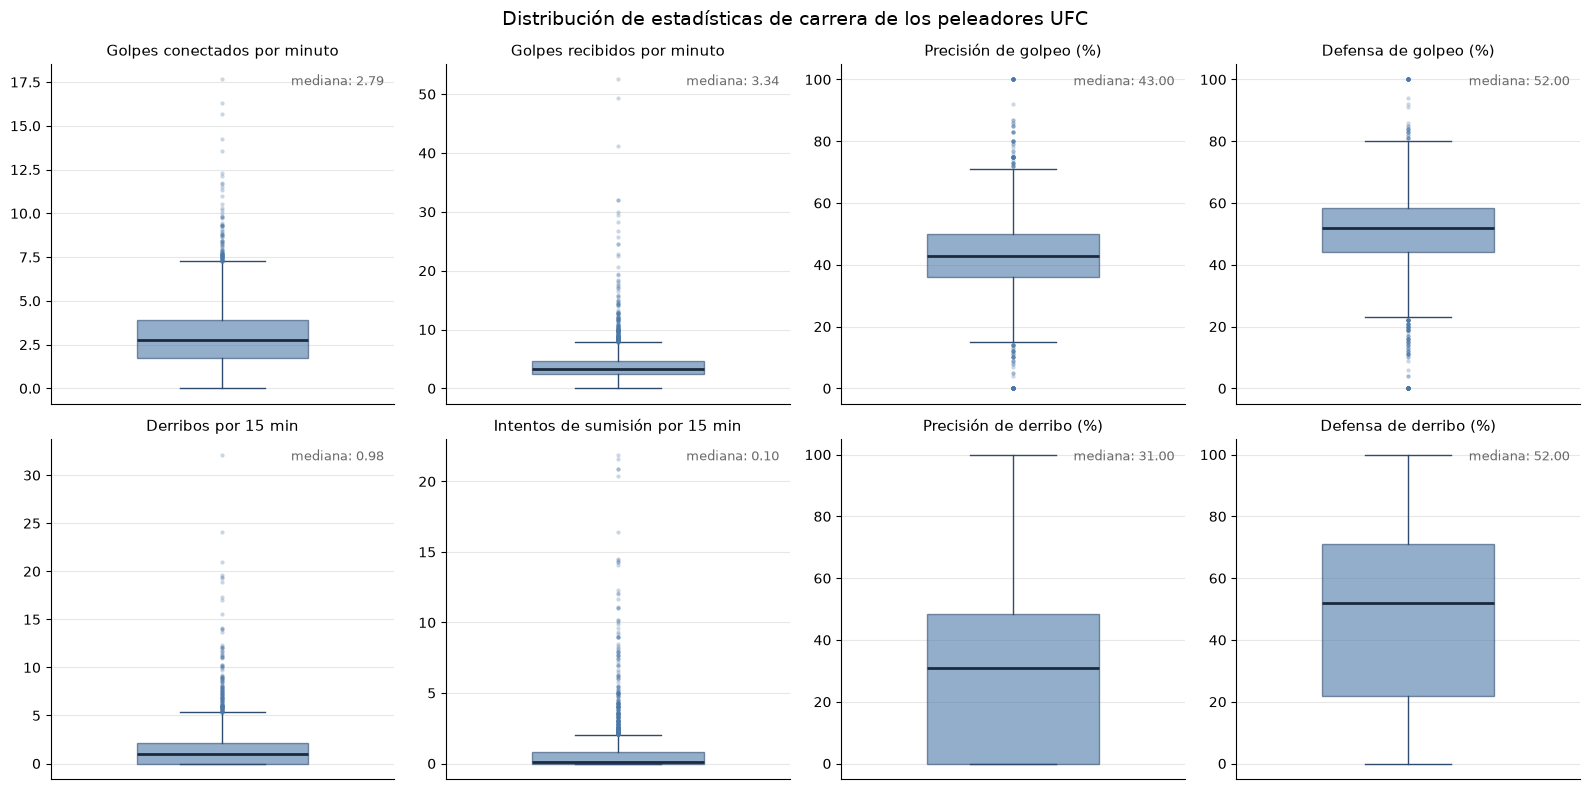

In [ ]:
estadisticas = {
    "slpm": "Golpes conectados por minuto",
    "sapm": "Golpes recibidos por minuto",
    "str_acc": "Precisión de golpeo (%)",
    "str_def": "Defensa de golpeo (%)",
    "td_avg": "Derribos por 15 min",
    "sub_avg": "Intentos de sumisión por 15 min",
    "td_acc": "Precisión de derribo (%)",
    "td_def": "Defensa de derribo (%)",
}
cols = list(estadisticas)

# Peleadores sin estadísticas registradas tienen todo en 0: se excluyen
stats_df = fighter_df.loc[~(fighter_df[cols] == 0).all(axis=1), cols]
print(f"Peleadores con estadísticas: {len(stats_df)} de {len(fighter_df)}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (col, titulo) in zip(axes.flat, estadisticas.items()):
    datos = stats_df[col].dropna()
    ax.boxplot(
        datos,
        widths=0.5,
        patch_artist=True,
        boxprops=dict(facecolor="#4C78A8", alpha=0.6, edgecolor="#2F4B6E"),
        medianprops=dict(color="#1B2A3D", linewidth=2),
        whiskerprops=dict(color="#2F4B6E"),
        capprops=dict(color="#2F4B6E"),
        flierprops=dict(
            marker="o",
            markersize=3,
            markerfacecolor="#4C78A8",
            markeredgecolor="none",
            alpha=0.3,
        ),
    )
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(
        0.97,
        0.97,
        f"mediana: {datos.median():.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color="dimgray",
    )

fig.suptitle(
    "Distribución de estadísticas de carrera de los peleadores UFC", fontsize=14
)
fig.tight_layout()
plt.show()

Peleadores en la regresión: 3659 (excluidos 168 sin peleas en fight.csv)


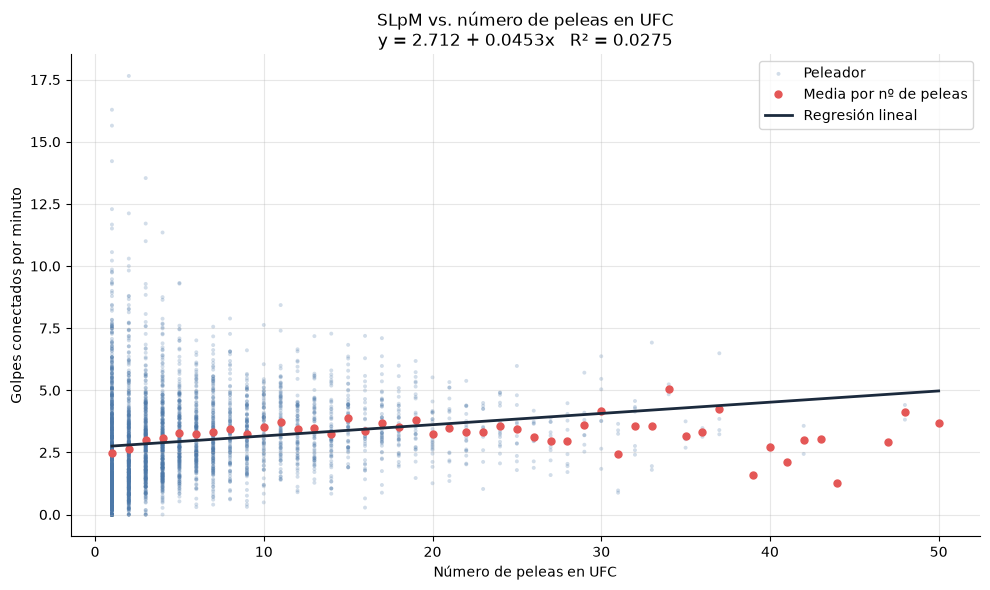

intercepto       2.7115
pendiente        0.0453
error_std        0.0045
t               10.1597
R2               0.0275
RMSE             1.7851
n             3659.0000
dtype: float64

In [ ]:
# Regresión: SLpM ~ número de peleas en UFC
fight_df = pd.read_csv("fight.csv")

# Cada pelea cuenta para ambos peleadores (esquina roja y azul)
n_peleas = pd.concat([fight_df["r_id"], fight_df["b_id"]]).value_counts()

peleas_df = fighter_df.loc[
    stats_df.index, ["fighter_id", "fighter_name", "slpm"]
].copy()
peleas_df["n_peleas"] = peleas_df["fighter_id"].map(n_peleas).fillna(0).astype(int)

# Se excluyen peleadores con estadísticas pero sin peleas registradas en fight.csv
sin_peleas = (peleas_df["n_peleas"] == 0).sum()
peleas_df = peleas_df[peleas_df["n_peleas"] > 0]
print(
    f"Peleadores en la regresión: {len(peleas_df)} (excluidos {sin_peleas} sin peleas en fight.csv)"
)

X = peleas_df[["n_peleas"]].to_numpy(float)
y = peleas_df["slpm"].to_numpy(float)
modelo = LinearRegression().fit(X, y)
y_pred = modelo.predict(X)

n = len(y)
x = X[:, 0]
residuos = y - y_pred
se = np.sqrt(residuos @ residuos / (n - 2) / ((x - x.mean()) ** 2).sum())
pendiente, intercepto = modelo.coef_[0], modelo.intercept_
r2 = r2_score(y, y_pred)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, s=8, alpha=0.25, color="#4C78A8", edgecolors="none", label="Peleador")
# Media de SLpM por número de peleas, como referencia frente a la recta
medias = peleas_df.groupby("n_peleas")["slpm"].mean()
ax.plot(
    medias.index,
    medias.values,
    "o",
    color="#E45756",
    markersize=5,
    label="Media por nº de peleas",
)
xs = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
ax.plot(xs, modelo.predict(xs), color="#1B2A3D", linewidth=2, label="Regresión lineal")
ax.set_title(
    f"SLpM vs. número de peleas en UFC\ny = {intercepto:.3f} + {pendiente:.4f}x   R² = {r2:.4f}",
    fontsize=12,
)
ax.set_xlabel("Número de peleas en UFC")
ax.set_ylabel(estadisticas["slpm"])
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
fig.tight_layout()
plt.show()

pd.Series(
    {
        "intercepto": intercepto,
        "pendiente": pendiente,
        "error_std": se,
        "t": pendiente / se,
        "R2": r2,
        "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
        "n": n,
    }
).round(4)

Peleadores en la regresión: 3659 (excluidos 168 sin peleas en fight.csv)


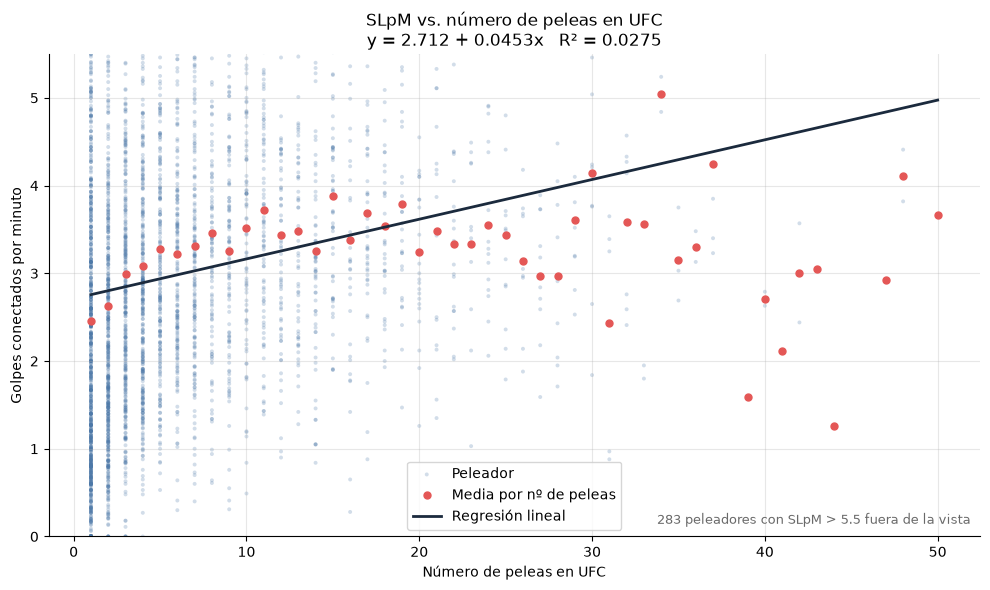

intercepto       2.7115
pendiente        0.0453
error_std        0.0045
t               10.1597
R2               0.0275
RMSE             1.7851
n             3659.0000
dtype: float64

In [ ]:
# Regresión: SLpM ~ número de peleas en UFC
fight_df = pd.read_csv("fight.csv")

# Cada pelea cuenta para ambos peleadores (esquina roja y azul)
n_peleas = pd.concat([fight_df["r_id"], fight_df["b_id"]]).value_counts()

peleas_df = fighter_df.loc[
    stats_df.index, ["fighter_id", "fighter_name", "slpm"]
].copy()
peleas_df["n_peleas"] = peleas_df["fighter_id"].map(n_peleas).fillna(0).astype(int)

# Se excluyen peleadores con estadísticas pero sin peleas registradas en fight.csv
sin_peleas = (peleas_df["n_peleas"] == 0).sum()
peleas_df = peleas_df[peleas_df["n_peleas"] > 0]
print(
    f"Peleadores en la regresión: {len(peleas_df)} (excluidos {sin_peleas} sin peleas en fight.csv)"
)

X = peleas_df[["n_peleas"]].to_numpy(float)
y = peleas_df["slpm"].to_numpy(float)
modelo = LinearRegression().fit(X, y)
y_pred = modelo.predict(X)

n = len(y)
x = X[:, 0]
residuos = y - y_pred
se = np.sqrt(residuos @ residuos / (n - 2) / ((x - x.mean()) ** 2).sum())
pendiente, intercepto = modelo.coef_[0], modelo.intercept_
r2 = r2_score(y, y_pred)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, s=8, alpha=0.25, color="#4C78A8", edgecolors="none", label="Peleador")
# Media de SLpM por número de peleas, como referencia frente a la recta
medias = peleas_df.groupby("n_peleas")["slpm"].mean()
ax.plot(
    medias.index,
    medias.values,
    "o",
    color="#E45756",
    markersize=5,
    label="Media por nº de peleas",
)
xs = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
ax.plot(xs, modelo.predict(xs), color="#1B2A3D", linewidth=2, label="Regresión lineal")
ax.set_title(
    f"SLpM vs. número de peleas en UFC\ny = {intercepto:.3f} + {pendiente:.4f}x   R² = {r2:.4f}",
    fontsize=12,
)
ax.set_xlabel("Número de peleas en UFC")
ax.set_ylabel(estadisticas["slpm"])
# Solo se acota la vista: la regresión y las medias usan todos los datos
ax.set_ylim(0, 5.5)
fuera = (y > 5.5).sum()
ax.text(
    0.99,
    0.02,
    f"{fuera} peleadores con SLpM > 5.5 fuera de la vista",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    color="dimgray",
)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
fig.tight_layout()
plt.show()

pd.Series(
    {
        "intercepto": intercepto,
        "pendiente": pendiente,
        "error_std": se,
        "t": pendiente / se,
        "R2": r2,
        "RMSE": np.sqrt(mean_squared_error(y, y_pred)),
        "n": n,
    }
).round(4)

Peleadores con más de 4 peleas: 1543 de 3659
Lambdas de Yeo-Johnson: {'slpm': np.float64(0.475), 'td_avg': np.float64(-0.179), 'sub_avg': np.float64(-1.057)}


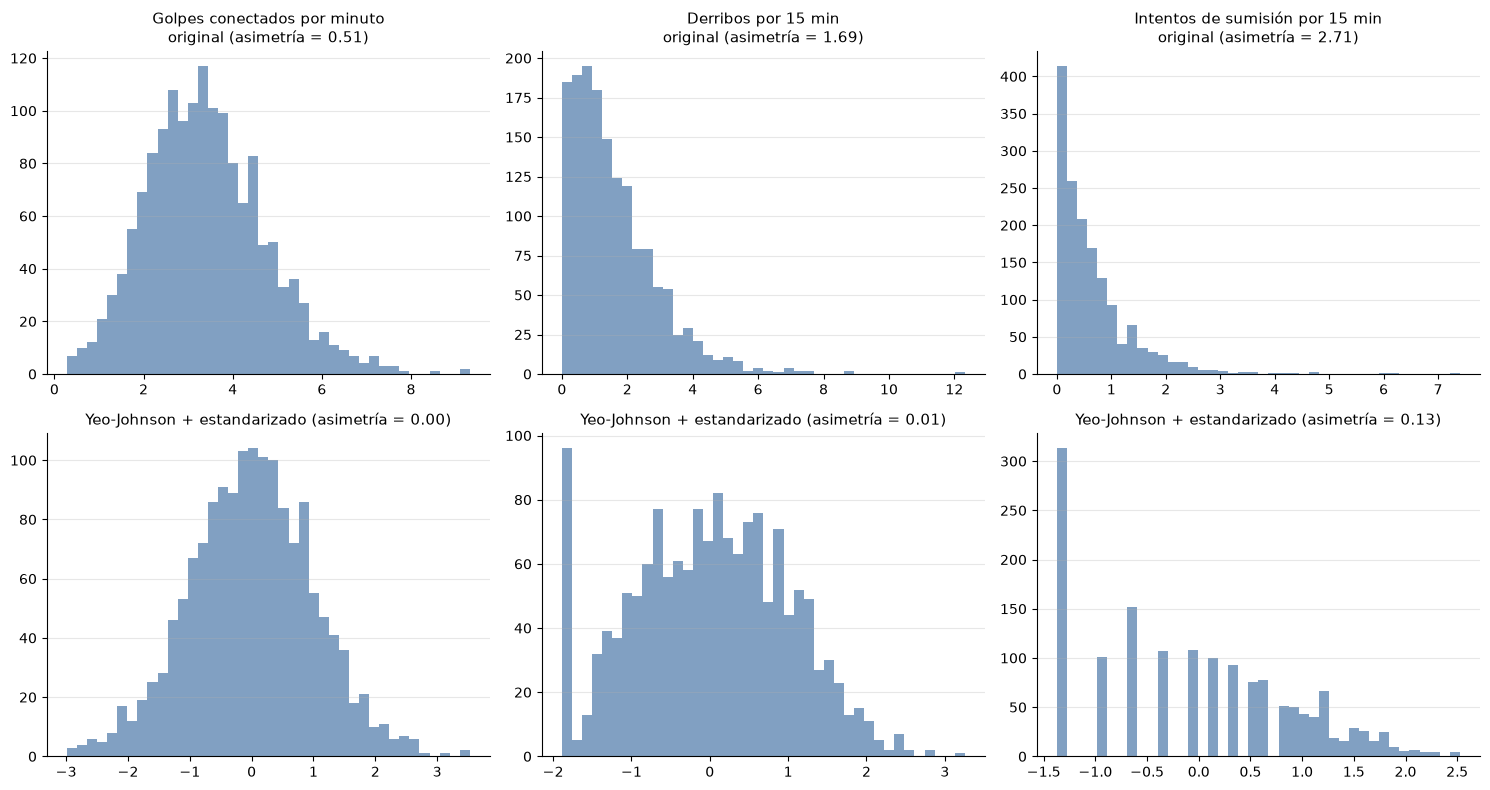

,slpm,td_avg,sub_avg
count,1543.000,1543.000,1543.000
mean,-0.000,0.000,0.000
std,1.000,1.000,1.000
min,-2.988,-1.888,-1.372
25%,-0.662,-0.727,-0.955
50%,0.004,0.024,-0.068
75%,0.684,0.725,0.774
max,3.529,3.256,2.526


In [10]:
from sklearn.preprocessing import PowerTransformer

# Se quitan los peleadores con 4 o menos peleas (sus estadísticas son muy inestables)
variables = ["slpm", "td_avg", "sub_avg"]
experimentados = peleas_df.loc[
    peleas_df["n_peleas"] > 4, ["fighter_id", "fighter_name", "n_peleas"]
]
ofensiva_df = experimentados.join(fighter_df[variables])
print(f"Peleadores con más de 4 peleas: {len(ofensiva_df)} de {len(peleas_df)}")

# Yeo-Johnson (admite ceros) + estandarización a media 0 y desviación 1
pt = PowerTransformer(method="yeo-johnson", standardize=True)
transformado_df = pd.DataFrame(
    pt.fit_transform(ofensiva_df[variables]),
    columns=variables,
    index=ofensiva_df.index,
)
print("Lambdas de Yeo-Johnson:", dict(zip(variables, pt.lambdas_.round(3))))

# Comparación de distribuciones antes y después
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, col in enumerate(variables):
    axes[0, j].hist(ofensiva_df[col], bins=40, color="#4C78A8", alpha=0.7)
    axes[0, j].set_title(
        f"{estadisticas[col]}\noriginal (asimetría = {ofensiva_df[col].skew():.2f})",
        fontsize=11,
    )
    axes[1, j].hist(transformado_df[col], bins=40, color="#4C78A8", alpha=0.7)
    axes[1, j].set_title(
        f"Yeo-Johnson + estandarizado (asimetría = {transformado_df[col].skew():.2f})",
        fontsize=11,
    )
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

transformado_df.describe().round(3)